In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm

d = np.load('plots/k20_300_big.npz', allow_pickle=True)
t        = d['t']                  # (n,)
k        = d['k_params'][:, 0]    # (n,)   VC0 spring param
fv       = d['f_virtual']         # (n, 3) Fx, Fy, Fz
goal     = d['goal']              # (n, N_VC, 3)
comp_pos = d['comp_pos']          # (n, N_VC, 3)

print(f'Total samples : {len(t)}')
print(f'Duration      : {t[-1]:.1f} s')
print(f'k values      : {sorted(np.unique(np.round(k, 1)))}')

Total samples : 192133
Duration      : 647.0 s
k values      : [np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(80.0), np.float64(100.0), np.float64(120.0), np.float64(140.0), np.float64(160.0), np.float64(180.0), np.float64(200.0), np.float64(220.0), np.float64(240.0), np.float64(260.0), np.float64(280.0), np.float64(300.0)]


In [2]:
# Filter: remove k=200 segments that appear BEFORE the first k=180
# k=200 was used as a correction step between sweeps;
# the final k=200 segment (after k=180 was first reached) is a real data point.

idx_first_k180 = np.where(np.abs(k - 180.0) < 1.0)[0][0]
t_k180 = t[idx_first_k180]
print(f'First k=180 at t = {t_k180:.2f} s  (index {idx_first_k180})')

mask_remove = (np.abs(k - 200.0) < 1.0) & (t < t_k180)
keep = ~mask_remove

print(f'Removed {mask_remove.sum():,} samples  ({mask_remove.sum()/len(t)*100:.1f}%)')
print(f'Kept    {keep.sum():,} samples')

t_f        = t[keep]
k_f        = k[keep]
fv_f       = fv[keep]
goal_f     = goal[keep]
comp_pos_f = comp_pos[keep]

First k=180 at t = 401.35 s  (index 116458)
Removed 23,250 samples  (12.1%)
Kept    168,883 samples


/tmp/ipykernel_218022/1434392081.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap     = cm.get_cmap('plasma', len(k_levels))


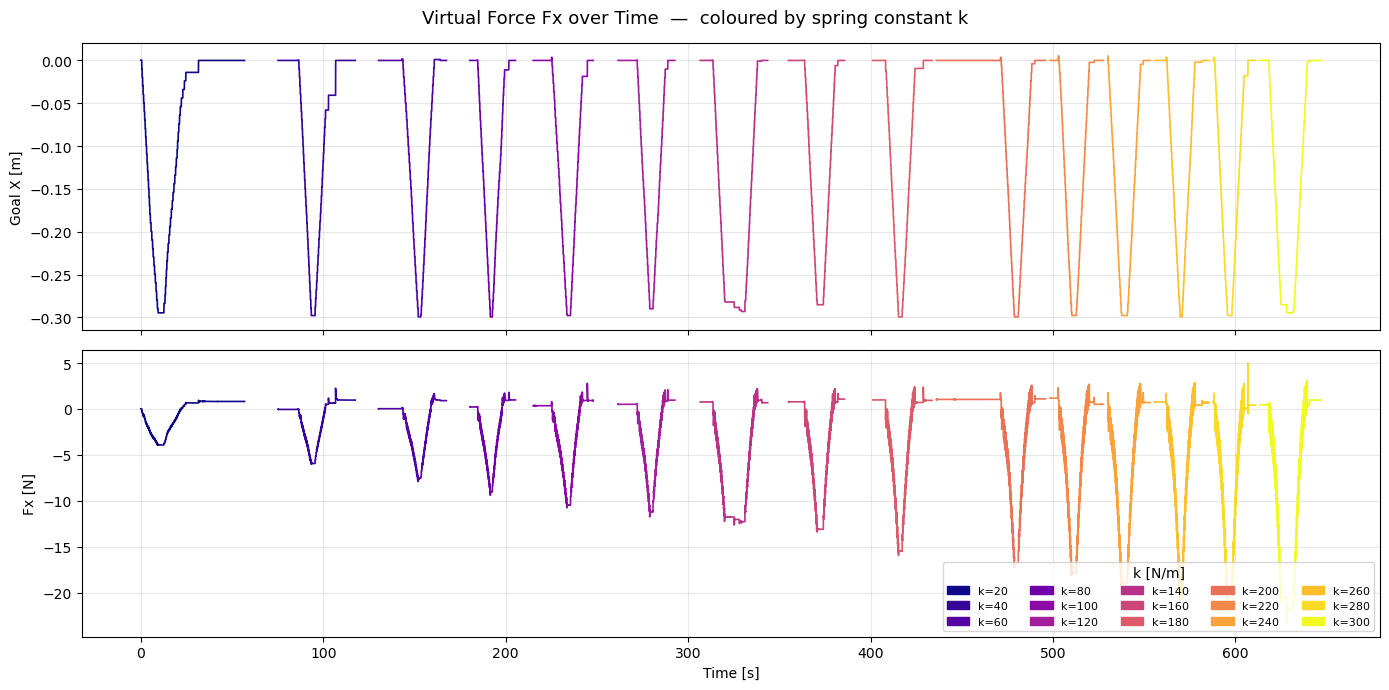

[OK] Saved -> plots/k20_300_force_vs_k.png


In [4]:
# Plot: goal-X + Fx over time, each k-segment coloured differently

k_levels = sorted(np.unique(np.round(k_f, 1)))
cmap     = cm.get_cmap('plasma', len(k_levels))
k_color  = {kv: cmap(i) for i, kv in enumerate(k_levels)}

# Split into contiguous k-segments
seg_breaks = np.where(np.diff(np.round(k_f, 1)) != 0)[0] + 1
segments   = np.split(np.arange(len(t_f)), seg_breaks)

fig, (ax_pos, ax_force) = plt.subplots(2, 1, sharex=True, figsize=(14, 7))
fig.suptitle('Virtual Force Fx over Time  —  coloured by spring constant k', fontsize=13)

for seg in segments:
    if len(seg) == 0:
        continue
    kval = round(float(k_f[seg[0]]), 1)
    c    = k_color[kval]
    ax_pos.plot(t_f[seg],   goal_f[seg, 0, 0], color=c, linewidth=1.2)
    ax_force.plot(t_f[seg], fv_f[seg, 0],       color=c, linewidth=1.2)

handles = [
    mpatches.Patch(color=k_color[kv], label=f'k={kv:.0f}')
    for kv in k_levels
]
ax_force.legend(handles=handles, ncol=5, fontsize=8,
                loc='lower right', title='k [N/m]')

ax_pos.set_ylabel('Goal X [m]')
ax_pos.grid(True, alpha=0.3)

ax_force.set_ylabel('Fx [N]')
ax_force.set_xlabel('Time [s]')
ax_force.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plots/k20_300_force_vs_k.png', dpi=200, bbox_inches='tight')
plt.show()
print('[OK] Saved -> plots/k20_300_force_vs_k.png')